# Predicción de cancelaciones de reservas hoteleras
## Notebook 01 · Descripción del problema y preprocesamiento

**Modelos y Simulación de Sistemas II – Universidad de Antioquia**
Juan Camilo Morales Villada · Juan Sebastián Andraus López · Jose Miguel Fajardo Fernández

Este notebook reproduce las Secciones I a III del informe: el análisis exploratorio, los datos faltantes,
la evidencia de fuga de información, la limpieza y la codificación de las variables.
Los modelos (Sección IV) están en el notebook 02 y la reducción de dimensión (Sección V) en el notebook 03.

**Cómo ejecutarlo:** en Google Colab basta con ejecutar las celdas en orden (la primera descarga el repositorio).
En el computador: clonar el repositorio, instalar `requirements.txt` y ejecutar desde la carpeta `notebooks/`.
El archivo `data/hotel_booking.csv` está incluido en el repositorio.

## 1. Configuración

In [1]:
# Solo en Google Colab: descarga el repositorio y se ubica en la carpeta notebooks/
import os, subprocess, sys
REPO = "https://github.com/Moraa0711/ModelosII-Proyecto-HotelBooking.git"
if "google.colab" in sys.modules:
    destino = "/content/ModelosII-Proyecto-HotelBooking"
    if not os.path.exists(destino):
        subprocess.run(["git", "clone", "-q", REPO, destino], check=True)
    os.chdir(os.path.join(destino, "notebooks"))

In [2]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

# Raíz del repositorio (funciona si se ejecuta desde notebooks/ o desde la raíz)
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(RAIZ))
from src import preprocesamiento as pp

RUTA_DATOS = RAIZ / "data" / "hotel_booking.csv"
RUTA_FIGURAS = RAIZ / "figuras"
RUTA_FIGURAS.mkdir(exist_ok=True)
SEMILLA = 42

pd.set_option("display.max_columns", 50)
plt.rcParams.update({"font.family": "serif", "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False})
print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| numpy", np.__version__)

pandas 3.0.5 | scikit-learn 1.9.1 | numpy 2.5.3


## 2. Descripción del problema

### 2.1 Contexto
Las cancelaciones afectan la planeación de la ocupación y los ingresos de un hotel. El objetivo es predecir,
a partir de la información disponible al momento de la reserva, si esta será cancelada (`is_canceled = 1`) o no (`0`).

### 2.2 Composición de la base de datos
Se usa la versión de Kaggle del dataset *Hotel Booking Demand* (Antonio, de Almeida y Nunes, 2019).

In [3]:
df = pp.cargar_datos(RUTA_DATOS)
print(f"Muestras: {df.shape[0]:,} | Variables: {df.shape[1]}")
df.head(3)

Muestras: 119,390 | Variables: 36


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,name,email,phone-number,credit_card
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01,Ernest Barnes,Ernest.Barnes31@outlook.com,669-792-1661,************4322
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01,Andrea Baker,Andrea_Baker94@aol.com,858-637-6955,************9157
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02,Rebecca Parker,Rebecca_Parker@comcast.net,652-885-2745,************3734


In [4]:
# Tipo de dato y número de valores distintos de cada variable
resumen = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "valores_distintos": df.nunique(),
    "faltantes": df.isna().sum(),
})
resumen

,tipo,valores_distintos,faltantes
hotel,str,2,0
is_canceled,int64,2,0
lead_time,int64,479,0
arrival_date_year,int64,3,0
arrival_date_month,str,12,0
arrival_date_week_number,int64,53,0
arrival_date_day_of_month,int64,31,0
stays_in_weekend_nights,int64,17,0
stays_in_week_nights,int64,35,0
adults,int64,14,0


Las columnas `name`, `email`, `phone-number` y `credit_card` fueron agregadas artificialmente por quien publicó
la versión de Kaggle; los datos originales tienen 32 variables.

### 2.3 Variable objetivo y análisis exploratorio

In [5]:
conteo = df[pp.OBJETIVO].value_counts().rename({0: "No cancelada", 1: "Cancelada"})
pd.DataFrame({"reservas": conteo, "porcentaje": (conteo / len(df) * 100).round(2)})

,reservas,porcentaje
is_canceled,,
No cancelada,75166,62.96
Cancelada,44224,37.04


In [6]:
# Tasa de cancelación por hotel
por_hotel = df.groupby("hotel")[pp.OBJETIVO].agg(reservas="size", tasa_cancelacion="mean")
por_hotel["tasa_cancelacion"] = (por_hotel["tasa_cancelacion"] * 100).round(2)
por_hotel

,reservas,tasa_cancelacion
hotel,,
City Hotel,79330,41.73
Resort Hotel,40060,27.76


In [7]:
# Tasa de cancelación según los días de anticipación (lead_time)
cortes = [-1, 7, 30, 90, 180, 365, df["lead_time"].max()]
etiquetas = ["0–7", "8–30", "31–90", "91–180", "181–365", ">365"]
tramo = pd.cut(df["lead_time"], cortes, labels=etiquetas)
tasa_lead = (df.groupby(tramo, observed=False)[pp.OBJETIVO].mean() * 100).round(1)
tasa_lead.to_frame("tasa_cancelacion_%")

,tasa_cancelacion_%
lead_time,
0–7,9.6
8–30,27.9
31–90,37.7
91–180,44.7
181–365,55.5
>365,67.7


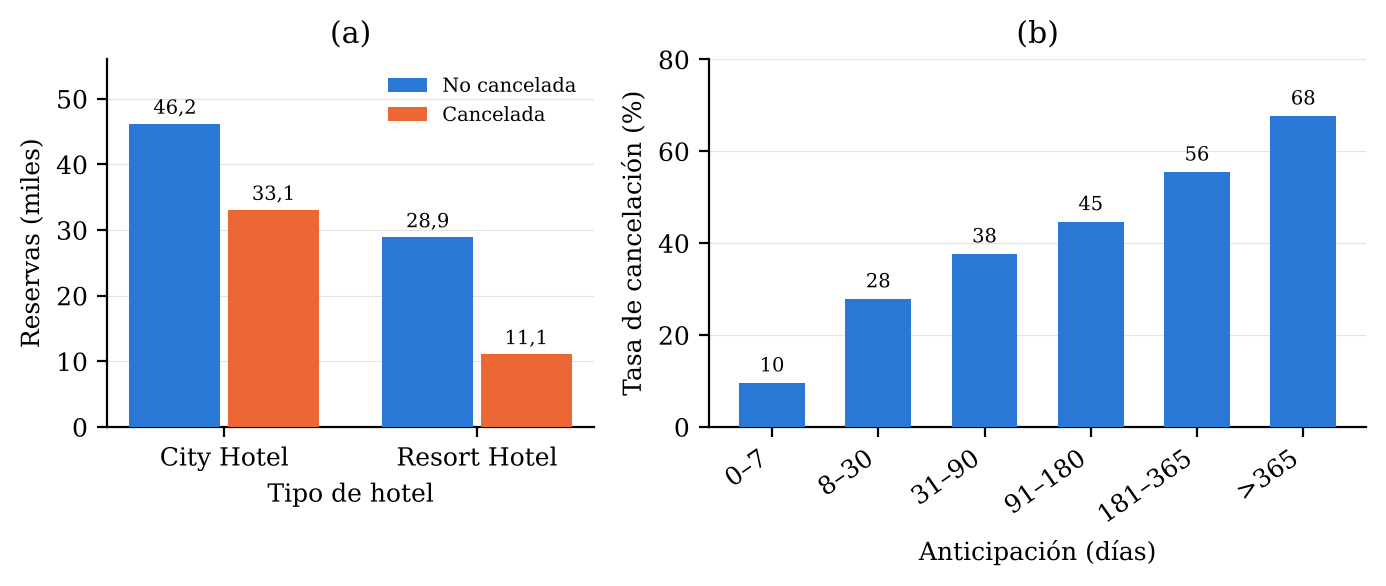

In [8]:
# Fig. 1 del informe
AZUL, NARANJA = "#2a78d6", "#eb6834"
fig, (a, b) = plt.subplots(1, 2, figsize=(7, 3), gridspec_kw={"width_ratios": [1, 1.35]})

ct = pd.crosstab(df["hotel"], df[pp.OBJETIVO])
x = np.arange(len(ct)); w = 0.36
for k, (col, color, nombre) in enumerate([(0, AZUL, "No cancelada"), (1, NARANJA, "Cancelada")]):
    barras = a.bar(x + (k - 0.5) * (w + 0.03), ct[col] / 1000, w, color=color, label=nombre, zorder=3)
    for r, v in zip(barras, ct[col]):
        a.text(r.get_x() + r.get_width() / 2, r.get_height() + 0.8, f"{v/1000:.1f}".replace(".", ","),
               ha="center", va="bottom", fontsize=7)
a.set_xticks(x, ["City Hotel", "Resort Hotel"])
a.set_xlabel("Tipo de hotel"); a.set_ylabel("Reservas (miles)"); a.set_ylim(0, 56)
a.legend(frameon=False, fontsize=7); a.set_title("(a)")

barras = b.bar(range(len(tasa_lead)), tasa_lead.values, 0.62, color=AZUL, zorder=3)
for r, v in zip(barras, tasa_lead.values):
    b.text(r.get_x() + r.get_width() / 2, v + 1.5, f"{v:.0f}", ha="center", va="bottom", fontsize=7)
b.set_xticks(range(len(tasa_lead)), etiquetas, rotation=35, ha="right")
b.set_xlabel("Anticipación (días)"); b.set_ylabel("Tasa de cancelación (%)"); b.set_ylim(0, 80)
b.set_title("(b)")
for ax in (a, b):
    ax.grid(axis="y", lw=0.4, color="#e4e3df", zorder=0)
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "fig1_exploratorio.png", dpi=300)
plt.show()

In [9]:
# Correlación de las variables numéricas con la variable objetivo
numericas = df.select_dtypes("number").drop(columns=[pp.OBJETIVO])
numericas.corrwith(df[pp.OBJETIVO]).sort_values(key=abs, ascending=False).round(3).to_frame("correlación")

,correlación
lead_time,0.293
total_of_special_requests,-0.235
required_car_parking_spaces,-0.195
booking_changes,-0.144
previous_cancellations,0.110
is_repeated_guest,-0.085
agent,-0.083
adults,0.060
previous_bookings_not_canceled,-0.057
days_in_waiting_list,0.054


### 2.4 Datos faltantes (Tabla II del informe)

In [10]:
faltantes = df.isna().sum()
faltantes = faltantes[faltantes > 0].to_frame("faltantes")
faltantes["porcentaje"] = (faltantes["faltantes"] / len(df) * 100).round(3)
faltantes["valores_distintos"] = [df[c].nunique() for c in faltantes.index]
faltantes

,faltantes,porcentaje,valores_distintos
children,4,0.003,5
country,488,0.409,177
agent,16340,13.686,333
company,112593,94.307,352


In [11]:
# La categoría 'Undefined' también representa ausencia de información
{c: int((df[c] == "Undefined").sum()) for c in ["meal", "market_segment", "distribution_channel"]}

{'meal': 1169, 'market_segment': 2, 'distribution_channel': 5}

### 2.5 Registros inconsistentes y atípicos

In [12]:
sin_huespedes = (df["adults"] + df["children"].fillna(0) + df["babies"]) == 0
print("Reservas sin huéspedes:", int(sin_huespedes.sum()))
print("adr negativo:", df.loc[df["adr"] < 0, "adr"].tolist())
print("adr mayor a 1.000:", df.loc[df["adr"] > 1000, "adr"].tolist())
print("Percentil 75 de adr:", df["adr"].quantile(0.75))

Reservas sin huéspedes: 180
adr negativo: [-6.38]
adr mayor a 1.000: [5400.0]
Percentil 75 de adr: 126.0


### 2.6 Evidencia de fuga de información
Una variable tiene fuga si contiene la respuesta o información que solo se conoce después de reservar.

In [13]:
# reservation_status coincide por completo con la variable objetivo
pd.crosstab(df["reservation_status"], df[pp.OBJETIVO])

is_canceled,0,1
reservation_status,,
Canceled,0,43017
Check-Out,75166,0
No-Show,0,1207


In [14]:
# assigned_room_type: la habitación se asigna después de reservar
distinta = df["reserved_room_type"] != df["assigned_room_type"]
(df.groupby(distinta.rename("habitación asignada distinta"))[pp.OBJETIVO].mean() * 100).round(2).to_frame("tasa_cancelacion_%")

,tasa_cancelacion_%
habitación asignada distinta,
False,41.56
True,5.38


In [15]:
# country: Portugal está sobrerrepresentado en las cancelaciones
con_pais = df[df["country"].notna()]
prt = (con_pais["country"] == "PRT")
(prt.groupby(con_pais[pp.OBJETIVO]).mean() * 100).round(2).rename({0: "no canceladas", 1: "canceladas"}).to_frame("% de reservas de Portugal")

,% de reservas de Portugal
is_canceled,
no canceladas,28.19
canceladas,62.32


Por esto se excluyen `reservation_status`, `reservation_status_date` y `assigned_room_type`. La variable `country`
se conserva, pero en el notebook 02 se comparan los modelos con y sin ella.

### 2.7 Filas repetidas

In [16]:
datos, bitacora = pp.limpiar_datos(df)
X_todo, _ = pp.separar_xy(datos)
grupos = pp.grupos_repetidos(datos)
tamano = pd.Series(grupos).map(pd.Series(grupos).value_counts()).to_numpy()
repetida = tamano > 1

print(f"Filas que se repiten al menos una vez: {repetida.sum():,} ({repetida.mean()*100:.1f} %)")
print(f"Copias adicionales (filas que sobrarían si se dejara una por grupo): {len(datos) - len(np.unique(grupos)):,}")
print(f"Grupo más grande: {tamano.max()} reservas idénticas")
print(f"Tasa de cancelación en filas repetidas: {datos.loc[repetida, pp.OBJETIVO].mean()*100:.1f} %")
print(f"Tasa de cancelación en filas únicas:    {datos.loc[~repetida, pp.OBJETIVO].mean()*100:.1f} %")
tasa_sin = datos.loc[~pd.Series(grupos).duplicated().to_numpy(), pp.OBJETIVO].mean() * 100
print(f"Tasa de cancelación si se eliminaran las copias: {tasa_sin:.1f} % (frente a {datos[pp.OBJETIVO].mean()*100:.1f} %)")

Filas que se repiten al menos una vez: 41,807 (35.1 %)
Copias adicionales (filas que sobrarían si se dejara una por grupo): 33,528
Grupo más grande: 180 reservas idénticas
Tasa de cancelación en filas repetidas: 57.3 %
Tasa de cancelación en filas únicas:    26.2 %
Tasa de cancelación si se eliminaran las copias: 27.6 % (frente a 37.1 %)


In [17]:
# ¿Qué tipo de reservas son las repetidas?
datos.loc[repetida, "market_segment"].value_counts(normalize=True).mul(100).round(1).to_frame("% de filas repetidas")

,% de filas repetidas
market_segment,
Groups,41.1
Offline TA/TO,30.2
Online TA,21.0
Corporate,3.9
Direct,3.6
Complementary,0.2
Aviation,0.0


Las filas repetidas corresponden principalmente a reservas de grupos y de agencias, que suelen hacerse (y cancelarse)
en bloque. Eliminarlas cambiaría la proporción de cancelaciones del problema, así que **se conservan**. Para evitar
que una misma reserva aparezca a la vez en entrenamiento y en prueba, las particiones del notebook 02 se hacen con
`StratifiedGroupKFold`, usando como grupo el conjunto de filas idénticas.

### 2.8 Limpieza

In [18]:
bitacora

,Paso,Filas,Columnas,Filas eliminadas
0,Base original,119390,36,0
1,Quitar 4 columnas sintéticas y 3 con fuga,119390,29,0
2,Imputar children y country; agent/company -> i...,119390,29,0
3,Quitar 'Undefined' en market_segment y distrib...,119385,29,5
4,Quitar reservas sin huéspedes,119205,29,180
5,Quitar adr negativo y adr atípico (5.400),119203,29,2


In [19]:
print(f"Base limpia: {datos.shape[0]:,} reservas y {len(pp.columnas_entrada())} variables de entrada")
print(f"Tasa de cancelación tras la limpieza: {datos[pp.OBJETIVO].mean()*100:.2f} %")

Base limpia: 119,203 reservas y 28 variables de entrada
Tasa de cancelación tras la limpieza: 37.07 %


### 2.9 Codificación
- Nominales (`hotel`, `meal`, `market_segment`, `distribution_channel`, `reserved_room_type`, `deposit_type`,
  `customer_type`): One-Hot.
- `country`: One-Hot agrupando en una sola categoría los países con menos de 100 reservas en el conjunto de entrenamiento.
- Numéricas y temporales: estandarización (media 0, desviación 1).
- Binarias (`is_repeated_guest`, `tiene_agente`, `tiene_compania`): sin cambios.

El codificador se ajusta **solo con los datos de entrenamiento** dentro de un `Pipeline` (notebook 02). Aquí se ajusta
con toda la base únicamente para mostrar cuántas variables resultan.

In [20]:
prep = pp.construir_preprocesador(incluir_pais=True)
X_cod = prep.fit_transform(X_todo)
nombres = prep.get_feature_names_out()
print(f"Variables después de codificar: {X_cod.shape[1]}")
pd.Series([n.split("_")[0] if n.startswith(("country", "reserved", "market", "distribution", "deposit", "customer"))
           else "otras" for n in nombres]).value_counts()

Variables después de codificar: 93


country         40
otras           26
reserved         9
market           7
distribution     4
customer         4
deposit          3
Name: count, dtype: int64

In [21]:
prep_sin_pais = pp.construir_preprocesador(incluir_pais=False)
print("Variables sin country:", prep_sin_pais.fit_transform(pp.separar_xy(datos, incluir_pais=False)[0]).shape[1])

Variables sin country: 53


### 2.10 Paradigma de aprendizaje
Aprendizaje **supervisado** de **clasificación binaria**: cada reserva tiene su etiqueta (`is_canceled`). Como las clases
están desbalanceadas, un clasificador que siempre prediga "no cancelada" ya acierta más del 60 % de las veces, así que la
exactitud no basta para evaluar los modelos:

In [22]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

_, y_todo = pp.separar_xy(datos)
base = DummyClassifier(strategy="most_frequent").fit(X_cod, y_todo)
pred = base.predict(X_cod)
print(f"Clasificador trivial -> exactitud: {accuracy_score(y_todo, pred):.4f} | F1 clase cancelada: {f1_score(y_todo, pred):.4f}")

Clasificador trivial -> exactitud: 0.6293 | F1 clase cancelada: 0.0000


## 3. Estado del arte (resumen)

| Ref. | Modelos | Validación | Mejor resultado |
|---|---|---|---|
| Adil et al. (2021) | LR, DT, AdaBoost, GB, RF + SMOTE / SMOTE-ENN | CV de 10 particiones | RF + SMOTE-ENN: exactitud > 95 % |
| Yang y Miao (2024) | GB, XGBoost, RF, Extra Trees, TNN | Partición temporal 75/25 | TNN: AUC-ROC 0,8554 (H1) y 0,8370 (H2) |
| Arasadina et al. (2026) | RF, XGBoost | Estratificada 70/15/15 | RF: AUC-ROC 0,9394; F1 0,8219 |
| Silvestre et al. (2026) | XGBoost | Temporal, ventana deslizante | AUC entre 0,85 y 0,99 |

Siguiente paso: **notebook 02** (Sección IV, entrenamiento y evaluación de los modelos).